# AMC 2026 – Round 3 · Notebook: the macro strategy
Financial Modeling (USI) · TA session 7

## Where we are

Last week, in TA session 6, we built our **quant sleeve** by combining the SAA and our four Round 2 stocks (NVDA, PEP, ABBV, DRI) with about 30 stocks from the BABQM screen (low beta, quality and momentum). Its tracking error relative to the SAA is about **2.2%**: the 5% target would allow 34% of the NAV in the quant stocks, and we cap the sleeve at 12.5% (quant notebook 02 §7, our sizing decision of 28 November).

Today, we will add the **macro strategy** from Class 7, using our remaining risk budget while keeping the **total tracking error below 7%**. We cap the macro sleeve at 7.5% of the NAV (§5).

## Today
| § | What | Minutes |
|---|---|---|
| 1 | The menu: seven macro strategies you can run **long-only**, four of them explained in short cards | 12 |
| 2 | Strategy A: regimes. Which asset class wins in which environment? | 15 |
| 3 | Strategy B: country value & momentum (**our TA example**) | 15 |
| 4 | Strategy C: the carry trade, and why its skewness matters | 8 |
| 5 | Size the macro sleeve inside the TE budget, and build the trades | 5 |
| 6 | Checkpoint 2: the macro page | 5 |

## The rules for the macro strategy (Round 3 guidelines + Class 7)

For the macro strategy, you can invest in the **yield curve, currencies, commodities, or country-level value and momentum strategies**. You can also build a strategy around a **global macroeconomic theme**.
- **How:** long-only, stocks and ETFs (inverse and leveraged ETFs are allowed).
- **Budget:** TE ≤ 7% for **all** deviations together: Round 2 stocks kept + quant + macro.


**Checkpoint 2, the macro page** (one page in the report, graded complete / incomplete):
1. **The view.** What you expect for the coming weeks (a regime change, the next central bank move, a rate gap), and the chain from this view to the position.
2. **The instruments.** The stocks or ETFs you buy, and why these.
3. **The risk.** What happens if the regime changes or the expected event does not come.
4. **The exit condition.** One observable event that would make you close the position: a data release (e.g. CPI above 4%), a central bank decision, a price level.

## 0. Settings

In [1]:
import numpy as np                     # arrays and matrix algebra
import pandas as pd                    # tables with dates
import matplotlib.pyplot as plt        # plots
pd.set_option("display.float_format", "{:.4f}".format)

# SAA of Round 1: our weights (data/holdings.json, as in quant 02 §0), unchanged in Round 3
W_SAA = pd.Series({"VTI": 0.1090, "VEA": 0.1024, "IEMG": 0.1023, "BND": 0.1333,
                   "BNDX": 0.1648, "TIP": 0.1526, "GLD": 0.1115, "BCI": 0.1240})   # BIL 0%; the rest (0.01%) is cash
SPLIT     = "2013-12-31"               # §3: tune on 2002-2013, validate on 2014-2026 (Class 4)
DISCOUNT  = 0.5                        # Class 4: halve the backtested Sharpe Ratio
WINDOW    = 60                         # months for the TE, as in Rounds 1-2-3
TE_MAX, TE_TARGET = 0.07, 0.065        # the budget, and our target (a small buffer for the price moves)
W_M_MAX   = 0.075                      # §5: cap on the macro sleeve, in % of the NAV: team decision of 28 Nov (reasons in §5)




ETFS = list(W_SAA.index)
R3 = "Data/"                           # the output of TA session 6: r3_prices.csv, r3_rf.csv, r3_portfolio.csv
N_TOP     = 4                          # §3: number of countries we buy (top ~20% of 18)
STRATEGY  = "V+M"                      # §3: the version that goes in the portfolio ("V+M", "Momentum" or "Value")


def stats(r, rf, bench):
    # the Class 2 / Class 4 measures of TA session 6, plus skewness (Checkpoint 2 asks for it)
    ex, exb = r - rf, bench - rf
    T = len(r) / 12
    beta, a = np.polyfit(exb, ex, 1)
    eps = ex - a - beta * exb
    IR = a * 12 / (eps.std() * np.sqrt(12)) if eps.std() > 0 else np.nan
    if r.equals(bench):
        beta, a, IR = 1.0, 0.0, np.nan
    wealth = (1 + r).cumprod()
    return pd.Series({"mean": r.mean() * 12, "vol": r.std() * np.sqrt(12),
                      "Sharpe": ex.mean() / r.std() * np.sqrt(12), "t(mean)": ex.mean() / r.std() * np.sqrt(12 * T),
                      "max drawdown": (wealth / wealth.cummax() - 1).min(), "worst month": r.min(),
                      "skewness": r.skew(), "beta": beta, "alpha": a * 12, "t(alpha)": IR * np.sqrt(T)})

## 1. Examples of macro strategies you can implement long-only

Today, we will focus on **three macro strategies**: regime tilt, country value & momentum, and carry.

| # | Strategy | View | Main risk | Exit signal |
|---|---|---|---|---|
| 1 | **Regime tilt** | Identify the current macro regime and overweight the best-performing asset class. | Incorrectly identifying the current regime | Indications of a regime change |
| 2 | **Country value & momentum** | Buy cheap markets (low P/B) with strong momentum (high 12-month returns). | Momentum crashes, value traps, currency risk | A country falls out of the top rankings |
| 3 | **Carry** | Buy higher-yielding currencies, earning the interest-rate differential if exchange rates remain stable. | Currency crashes during risk-off periods (negative skew) | Fed hikes or foreign central bank cuts |




### 1b. The four strategies we do not compute today


**Rate cycle: buy duration at the peak of the hikes**
- **View:** the Fed has stopped hiking and will cut. 
- **Signal:** the gap between the Taylor-rule rate and the Fed funds rate. Gap < 0 = policy is tight = room to cut.
$$r^{Taylor}_t = r^* + \pi_t + 0.5(\pi_t - 2\%) + 0.5\cdot\text{output gap}_t$$
- **Instruments:** TLT (20+ years) for a strong view, IEF (7–10 years) for a milder one. 
- **Risk / exit:** inflation comes back and the cuts are priced out (2022). 

**Yield curve: bet on the slope**
- **View:** the curve steepens, so long yields rise relative to short yields (e.g. the Fed cuts the short end, while long yields stay high).
- **Long-only version:** short-term bonds (SHY) + an inverse long-bond ETF.
- **Exit:** The yield curve starts to flatten, for example, when recession fears cause long-term yields to fall.

**Commodities and inflation protection**
- **View:** a **negative supply shock** (oil or gas cut, bad harvest, war). Inputs become scarce and expensive, so firms produce less and raise prices: output falls and inflation rises = **stagflation** (e.g. 2022).
- **Why these assets:**
  - **Commodities:** their price *is* the shock, so it rises.
  - **Energy and mining stocks:** they sell the commodity, so their profits rise with its price.
  - **Gold:** a store of value when inflation erodes cash and bonds.
  - **TIPS:** US government bonds whose principal is indexed to CPI, so they gain when inflation surprises up.
- **Exit:** oil falls, inflation surprises down, demand slows.

**Thematic macro**
- **View:** Invest in a major trend the market underestimates, such as AI, China's growth, or the energy transition.
- **Instruments:** Thematic ETFs (SMH, ICLN, MCHI) or selected stocks.
- **Main risk:** The trend may already be priced in. What does the market still underestimate?
- **Exit:** Set a catalyst and a deadline (e.g., earnings or policy decisions). Exit if the expected catalyst does not materialize.

## 2. Strategy A – regimes: which asset class wins in which environment?

*The TA's example of a regime rule (ISM PMI above 50, whole sample, every index in `r7_assets.csv`, including the TA's SPY, IEF, LQD and DBC), kept for reference: on our data it reads today as Overheating. Our rule is notebook 03b (CFNAI 3-month average, our SAA, picks made in real time): Stagflation → bonds: BNDX, with BND beside it (§5, `PICKS`).*
**The idea (Class 7):** demand shocks move growth and inflation in the **same** direction, supply shocks in **opposite** directions. This gives **four environments**.

**The two signals** :
- growth: ISM manufacturing PMI (monthly survey of US purchasing managers). Above 50 = manufacturing expands;
- inflation: CPI year-on-year (% change in US consumer prices vs 12 months earlier). Rising = higher than 12 months earlier.

$$g_t = \mathbb{1}\{PMI_t > 50\}, \qquad \iota_t = \mathbb{1}\{\pi_t > \pi_{t-12}\}$$



> **Note:** this is *my* rule, not *the* rule. There is no fixed way to classify regimes: choose your own signals and thresholds, test them and justify them.

Based on these two signals—**economic growth and inflation**—we can identify four different macroeconomic regimes.

| | Inflation falling | Inflation rising |
|---|---|---|
| **Growth up** | Goldilocks | Overheating |
| **Growth down** | Slowdown | Stagflation |

⚠️ **Avoid look-ahead bias:** Since PMI and CPI are published with a delay, we use the previous month's available data to identify the regime and evaluate next-month returns.

Each month, growth is 'up' if the PMI is above 50 and inflation is 'rising' if CPI y/y is above its value 12 months earlier;
the two together give the environment.

Jan 1991 - Oct 2026: 430 months. Months in each environment:
Goldilocks     141
Overheating    162
Stagflation     38
Slowdown        89

TODAY (latest prints, October 2026): OVERHEATING
  ISM Manufacturing PMI (PMI): 55.5  -> above 50
  US CPI inflation, y/y (CPI): 3.7% vs 3.0% a year earlier -> rising


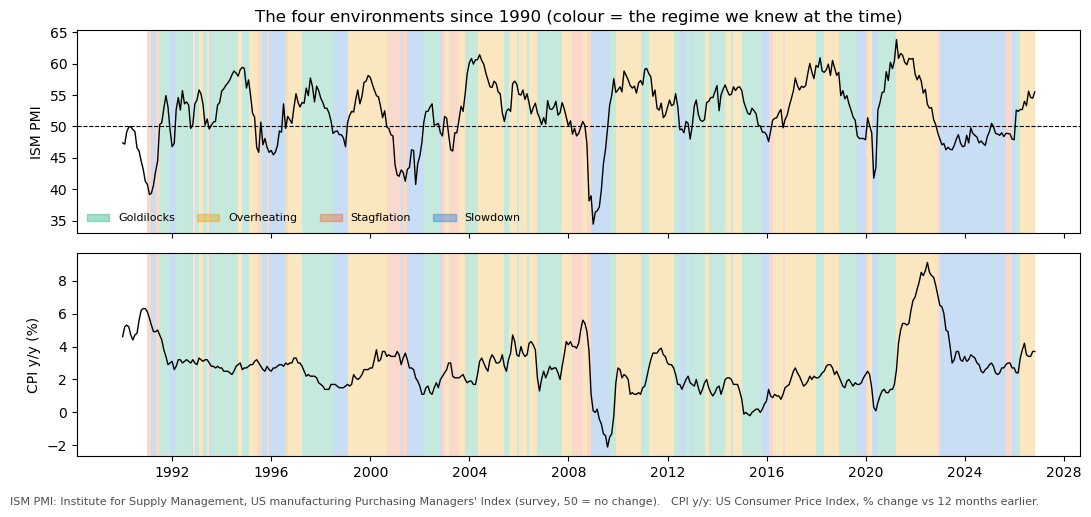

In [2]:
macro  = pd.read_csv("r7_macro.csv", index_col=0, parse_dates=True)
assets = pd.read_csv("r7_assets.csv", index_col=0, parse_dates=True)      # named after their SAA ETF
rf     = pd.read_csv("r7_rf_long.csv", index_col=0, parse_dates=True)["rf"]

sig    = macro[["PMI", "CPI_yoy"]].shift(1)                    # what we know at the end of month t
growth = sig["PMI"] > 50
infl   = sig["CPI_yoy"] > sig["CPI_yoy"].shift(12)
known  = sig["PMI"].notna() & sig["CPI_yoy"].shift(12).notna()
regime = pd.Series(np.select([growth & ~infl, growth & infl, ~growth & infl, ~growth & ~infl],
                             ["Goldilocks", "Overheating", "Stagflation", "Slowdown"], "?"), index=macro.index)[known]
ORDER  = ["Goldilocks", "Overheating", "Stagflation", "Slowdown"]
COL    = {"Goldilocks": "#1baf7a", "Overheating": "#eda100", "Stagflation": "#eb6834", "Slowdown": "#2a78d6"}

print("Each month, growth is 'up' if the PMI is above 50 and inflation is 'rising' if CPI y/y is above its value "
      "12 months earlier;\nthe two together give the environment.\n")
print(f"{regime.index[0]:%b %Y} - {regime.index[-1]:%b %Y}: {len(regime)} months. Months in each environment:")
print(regime.value_counts().reindex(ORDER).to_string())
# today: the latest prints we have (published before the trade date)
pmi_now, cpi_now, cpi_12 = macro["PMI"].iloc[-1], macro["CPI_yoy"].iloc[-1], macro["CPI_yoy"].iloc[-13]
today = {(True, False): "Goldilocks", (True, True): "Overheating", (False, True): "Stagflation",
         (False, False): "Slowdown"}[(pmi_now > 50, cpi_now > cpi_12)]
print(f"\nTODAY (latest prints, {macro.index[-1]:%B %Y}): {today.upper()}")
print(f"  ISM Manufacturing PMI (PMI): {pmi_now:.1f}  -> {'above' if pmi_now > 50 else 'below'} 50")
print(f"  US CPI inflation, y/y (CPI): {cpi_now:.1f}% vs {cpi_12:.1f}% a year earlier -> "
      f"{'rising' if cpi_now > cpi_12 else 'falling'}")

fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for d, k in regime.items():                                    # one coloured band per month
    for a in ax:
        a.axvspan(d - pd.offsets.MonthEnd(1), d, color=COL[k], alpha=0.25, lw=0)
ax[0].plot(macro["PMI"], color="k", lw=1); ax[0].axhline(50, color="k", ls="--", lw=0.8); ax[0].set_ylabel("ISM PMI")
ax[1].plot(macro["CPI_yoy"], color="k", lw=1); ax[1].set_ylabel("CPI y/y (%)")
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COL[k], alpha=0.4) for k in ORDER], labels=ORDER,
             ncol=4, loc="lower left", fontsize=8, frameon=False)
ax[0].set_title("The four environments since 1990 (colour = the regime we knew at the time)")
fig.text(0.01, -0.02, "ISM PMI: Institute for Supply Management, US manufacturing Purchasing Managers' Index (survey, 50 = no change).   "
         "CPI y/y: US Consumer Price Index, % change vs 12 months earlier.", fontsize=8, color="0.3")
plt.tight_layout(); plt.show()

### Which asset class wins in each environment?
For each SAA asset class $j$ (or any other ETF) and each environment $k$: average excess return of the **following** month (we only know the environment at the end of the month, so month $t+1$ is the first we can trade) and its Sharpe Ratio:

$$\hat\mu_{j,k} = \frac{1}{N_k}\sum_{t:\,s_t = k} R^e_{j,t+1}, \qquad SR_{j,k} = \frac{\hat\mu_{j,k}}{\hat\sigma_{j,k}}\sqrt{12}, \qquad t_{j,k} = SR_{j,k}\sqrt{N_k/12}$$

$N_k$ = number of months in environment $k$. 

In [3]:
NAMES = {"SPY": "US stocks", "IEF": "Treasuries", "TIP": "TIPS", "LQD": "Corp. bonds",
         "DBC": "Commodities", "GLD": "Gold"}                     # plain names instead of tickers
Re  = assets.pct_change(fill_method=None).sub(rf, axis=0).rename(columns=NAMES)   # monthly excess returns
nxt = Re.shift(-1).reindex(regime.index)                              # return of month t+1, next to the regime of month t
g   = nxt.groupby(regime)
SR  = (g.mean() / g.std() * np.sqrt(12)).reindex(ORDER)
N   = g.count().reindex(ORDER)
tst = SR * np.sqrt(N / 12)

print("Annualised Sharpe ratio in the month after each environment (rows = environment, columns = asset class)")
display(SR.style.format("{:.2f}").background_gradient(cmap="RdYlGn", axis=None, vmin=-1.5, vmax=1.5))

best = SR.idxmax(axis=1)
print("Best asset class in each environment (Sharpe, t-stat, months):")
for k in ORDER:
    b = best[k]
    print(f"  {k:12s} -> {b}: Sharpe {SR.loc[k, b]:.2f}, t = {tst.loc[k, b]:.1f}, {N.loc[k, b]} months"
          + ("" if abs(tst.loc[k, b]) > 2 else "   <- not significant: only a weak hint"))

Annualised Sharpe ratio in the month after each environment (rows = environment, columns = asset class)


,US stocks,Treasuries,TIPS,Corp. bonds,Commodities,Gold,VTI,VEA,IEMG,BND,BNDX
Goldilocks,0.96,0.55,0.43,0.70,0.34,-0.21,0.96,0.53,0.48,0.73,0.89
Overheating,0.32,0.42,0.23,0.08,0.04,0.27,0.29,0.07,0.09,0.27,0.41
Stagflation,0.18,0.94,1.09,1.55,0.37,0.62,0.25,0.14,0.27,1.42,1.42
Slowdown,0.92,-0.08,0.62,0.71,0.04,1.21,0.90,0.49,1.10,0.32,0.59


Best asset class in each environment (Sharpe, t-stat, months):
  Goldilocks   -> VTI: Sharpe 0.96, t = 3.3, 141 months
  Overheating  -> Treasuries: Sharpe 0.42, t = 1.5, 161 months   <- not significant: only a weak hint
  Stagflation  -> Corp. bonds: Sharpe 1.55, t = 2.7, 38 months
  Slowdown     -> Gold: Sharpe 1.21, t = 3.3, 89 months


**Reading the results** (vs. Class 7):

- **Goldilocks → US stocks:** Matches the textbook prediction and shows the strongest result (0.96, t = 3.3).
- **Overheating → No clear winner:** Treasuries perform best (0.42, t = 1.5), rather than commodities.
- **Stagflation → Bonds and TIPS:** Outperform stocks, but only 38 observations make the result less reliable.
- **Slowdown → Gold and stocks:** Surprisingly, stocks perform well as markets often recover before economic indicators (2009, 2023).


> **Limits:** this is a basic method: two signals, fixed thresholds, simple averages. More sophisticated approaches exist in the litterature. 

In [4]:
ETF = {"SPY": "SPDR S&P 500 ETF", "IEF": "iShares 7-10 Year Treasury Bond ETF", "TIP": "iShares TIPS Bond ETF",
       "LQD": "iShares iBoxx $ Investment Grade Corporate Bond ETF", "DBC": "Invesco DB Commodity Index Tracking Fund",
       "GLD": "SPDR Gold Shares"}
TICK = {v: k for k, v in NAMES.items()} if "NAMES" in globals() else {}    # plain name -> ticker (if columns were renamed)
lab  = lambda a: f"{ETF.get(TICK.get(a, a), TICK.get(a, a))} ({TICK.get(a, a)})"   # our ETFs (VTI, BNDX, …): ticker only
hi, lo = best[today], SR.loc[today].idxmin()

print(f"According to our method, today we are in {today.upper()}.")
print(f"  Historically, the best asset class of my SAA in this environment was {lab(hi)}, Sharpe {SR.loc[today, hi]:.2f};")
print(f"  the worst was {lab(lo)}, Sharpe {SR.loc[today, lo]:.2f}.")
print(f"-> a regime view would overweight the first and underweight the second, relative to the SAA.")


According to our method, today we are in OVERHEATING.
  Historically, the best asset class of my SAA in this environment was iShares 7-10 Year Treasury Bond ETF (IEF), Sharpe 0.42;
  the worst was Invesco DB Commodity Index Tracking Fund (DBC), Sharpe 0.04.
-> a regime view would overweight the first and underweight the second, relative to the SAA.



## 3. Strategy B – Country value & momentum

*The TA's example of a country strategy (raw P/B, every country in `r7_countries.csv`), kept for reference. Our country strategy is notebook 04; our macro position is Strategy A (notebook 03b), set in §5 (`PICKS`).*

**The idea:** Apply the Class 6 value and momentum factors to **countries instead of individual stocks**. Buy cheap markets (value) and recent winners (momentum). Since the two factors tend to be negatively correlated, combining them can help diversify risk.

Unlike last week's quant strategy, country ETFs also expose investors to **currency risk**.

**Data to be downloaded:** Total-return index of each country ETF and the price-to-book ratio of each country's MSCI index.

**Signals** at the end of each month $t$, for each country $c$:

**Momentum:** Measures the country's past return, excluding the most recent month.

$$MOM_{c,t} = \frac{P_{c,t-1}}{P_{c,t-12}} - 1$$

**Value:** Measures how cheap a country's stock market is. Higher values indicate cheaper markets.

$$VAL_{c,t} = \frac{B}{P}_{c,t} = \frac{1}{P/B_{c,t}}$$

**Combined score:** Averages the momentum and value rankings to identify the most attractive countries.

$$Score_{c,t} = \tfrac{1}{2}\big[\text{Rank}_{c,t}(MOM) + \text{Rank}_{c,t}(VAL)\big]$$

**My portfolio construction rules:**



| Choice | Rule |
|---|---|
| **Universe** | 18 markets: 17 iShares MSCI country ETFs + S&P 500 ETF (US), all in USD |
| **Selection** | Select the top 4 countries based on each strategy's score |
| **Weights** | Invest equally in the 4 selected countries, without short selling |
| **Rebalancing** | Rebalance monthly using the previous month's scores |



BACKTEST Feb 2002 - Oct 2026 (297 months). Benchmark: equally weighted strategy with the 18 countries
alpha, beta = regression of each strategy's excess return on the benchmark's excess return (all 18 countries, equal weights


,Momentum,Value,V+M,All countries
mean,0.11,0.11,0.09,0.10
vol,0.20,0.20,0.19,0.18
Sharpe,0.45,0.45,0.40,0.45
t(mean),2.25,2.22,1.97,2.25
max drawdown,-0.64,-0.54,-0.63,-0.58
worst month,-0.27,-0.22,-0.24,-0.24
skewness,-0.52,-0.13,-0.48,-0.58
beta,1.01,1.04,0.99,1.00
alpha,0.01,0.00,-0.01,0.00
t(alpha),0.44,0.30,-0.43,nan


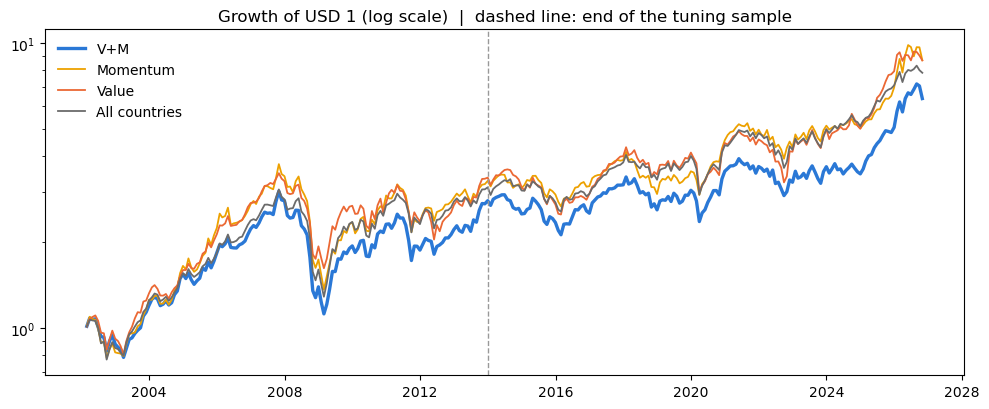

In [5]:
P   = pd.read_csv("r7_countries.csv", index_col=0, parse_dates=True)
pb  = pd.read_csv("r7_pb.csv", index_col=0, parse_dates=True).reindex(index=P.index, columns=P.columns)
R_c = P.pct_change(fill_method=None)

mom = P.shift(1) / P.shift(12) - 1
val = 1 / pb
rk  = lambda x: x.rank(axis=1, pct=True) * 100                     # percentile rank across countries, 100 = best
scores = {"Momentum": rk(mom), "Value": rk(val)}
scores["V+M"] = ((scores["Momentum"] + scores["Value"]) / 2).fillna(scores["Momentum"])   # no P/B -> momentum only

def top_weights(score, n=N_TOP):
    # equal weights on the n countries with the highest score; NaN rows (no signal yet) stay NaN
    pick = score.rank(axis=1, ascending=False, method="first") <= n
    w = pick.astype(float).div(pick.sum(axis=1), axis=0)
    return w.where(score.notna().sum(axis=1) >= n)

# weights chosen at the end of month t, return earned in month t+1
bt = pd.DataFrame({k: (top_weights(s).shift(1) * R_c).sum(axis=1, min_count=1) for k, s in scores.items()})
bt["All countries"] = R_c.mean(axis=1)
bt = bt.dropna()
rf_bt = rf.reindex(bt.index).ffill()
BENCH = "All countries"

res = bt.apply(lambda r: stats(r, rf_bt, bt[BENCH]))
print(f"BACKTEST {bt.index[0]:%b %Y} - {bt.index[-1]:%b %Y} ({len(bt)} months). Benchmark: equally weighted strategy with the 18 countries")
print("alpha, beta = regression of each strategy's excess return on the benchmark's excess return (all 18 countries, equal weights")
display(res.style.format("{:.2f}"))

fig, ax = plt.subplots(figsize=(10, 4.2))
for k, c in {"V+M": "#2a78d6", "Momentum": "#eda100", "Value": "#eb6834", BENCH: "#6b6b6b"}.items():
    ax.plot((1 + bt[k]).cumprod(), color=c, lw=2.4 if k == STRATEGY else 1.3, label=k)
ax.axvline(pd.Timestamp(SPLIT), color="#999", ls="--", lw=1)
ax.set_yscale("log"); ax.set_title("Growth of USD 1 (log scale)  |  dashed line: end of the tuning sample")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Reading the results:**
- **No signal beats the benchmark.**
- **Combining did not help here:** unlike stocks last week, V+M is worse than each signal alone.



### Robustness check (Class 4)
- **Split:** Develop the strategy using 2002–2013 data, then test it on 2014–2026.
- **Discount:** Halve the backtested Sharpe Ratio to account for overfitting.
- **Count the trials:** Keep track of every strategy variation tested.

In [6]:
periods = {"tuning 2002-2013": bt.loc[:SPLIT], "validation 2014-2026": bt.loc[SPLIT:].iloc[1:]}
val_tab = pd.concat({p: x.apply(lambda r: stats(r, rf_bt.loc[r.index], x[BENCH]))[[STRATEGY, BENCH]]
                     for p, x in periods.items()}, axis=1)
display(val_tab.loc[["mean", "vol", "Sharpe", "alpha", "t(alpha)", "max drawdown"]].style.format("{:.2f}"))

SR_bt, SR_val = res.loc["Sharpe", STRATEGY], val_tab.loc["Sharpe", ("validation 2014-2026", STRATEGY)]
SR_real = DISCOUNT * SR_bt
print(f"{STRATEGY}: Sharpe backtest {SR_bt:.2f} | validation {SR_val:.2f} | realistic (÷2) {SR_real:.2f} | "
      f"benchmark {res.loc['Sharpe', BENCH]:.2f}")
print("Variations tried: 3 (Momentum, Value, V+M) ")

V+M: Sharpe backtest 0.40 | validation 0.35 | realistic (÷2) 0.20 | benchmark 0.45
Variations tried: 3 (Momentum, Value, V+M) 


### Today's countries

 Before investing, **check concentration risk**: countries from the same region or with similar currency exposure may not provide much diversification.

In [7]:

country_names = {
    "EWZ": "Brazil", "EWJ": "Japan", "EWS": "Singapore",
    "EWY": "South Korea", "EWI": "Italy", "EWP": "Spain",
    "EWH": "Hong Kong", "EWT": "Taiwan", "EWG": "Germany",
    "EWW": "Mexico", "EWN": "Netherlands", "EWU": "United Kingdom",
    "EWC": "Canada", "EWQ": "France", "EWA": "Australia",
    "SPY": "United States", "EWD": "Sweden", "EWL": "Switzerland",
    "MCHI": "China", "INDA": "India", "EZA": "South Africa"   # added in notebook 01
}

last = P.index[-1]

today_tab = pd.DataFrame({
    "12-1m return": mom.loc[last],
    "P/B": pb.loc[last],
    "rank MOM": scores["Momentum"].loc[last],
    "rank VAL": scores["Value"].loc[last],
    "score": scores[STRATEGY].loc[last]
}).sort_values("score", ascending=False)

PICKS = list(today_tab.index[:N_TOP])
today_tab["Country"] = today_tab.index.map(country_names)
today_tab["buy"] = np.where(today_tab.index.isin(PICKS), "✔", "")

selected = ", ".join(f"{country_names[t]} ({t})" for t in PICKS)

print(f"Signals at the end of {last:%B %Y}.")
print(f"We invest in: {selected}")

display(today_tab.style.format({
    "12-1m return": "{:.1%}",
    "P/B": "{:.2f}",
    "rank MOM": "{:.0f}",
    "rank VAL": "{:.0f}",
    "score": "{:.0f}"
}))


Signals at the end of October 2026.
We invest in: Brazil (EWZ), Japan (EWJ), Singapore (EWS), South Korea (EWY)


,12-1m return,P/B,rank MOM,rank VAL,score,Country,buy
EWZ,25.0%,1.63,90,90,90,Brazil,✔
EWJ,21.9%,1.98,81,76,79,Japan,✔
EWS,21.9%,2.14,86,62,74,Singapore,✔
EWY,92.7%,2.32,100,48,74,South Korea,✔
EWI,17.1%,1.89,67,81,74,Italy,
EWP,21.5%,2.16,76,57,67,Spain,
EWH,7.7%,1.21,24,100,62,Hong Kong,
EWG,3.4%,1.79,19,86,52,Germany,
EWT,77.2%,5.34,95,10,52,Taiwan,
EWW,10.5%,2.32,48,52,50,Mexico,


**Reading the results:** 
- **Concentration:** Three of the four selected countries are in Asia, creating significant regional and semiconductor sector exposure.


## 4. Strategy C – the carry trade
**Carry Trade** = Borrow in a low-rate currency, invest in a high-rate one (Class 7):

$$R^{carry}_{t+1} = (1+i^*_t)\,\frac{S_t}{S_{t+1}} - (1+i_t)$$

$i^*$ = rate of the currency we buy, $i$ = rate of the currency we borrow, $S$ = units of the investment currency per unit of the funding currency. **Uncovered interest parity** predicts zero carry profits, but in practice, carry earns positive returns on average and suffers crashes during risk-off periods.

 Two versions:
- **Long-short** (the textbook trade): long the 3 highest-rate currencies, short the 3 lowest;
- **Long-only** (what you can do in the AMC): a USD investor buys the currencies whose rate is **above the US rate**.

**What the code does:**
- **Inputs:** monthly rates of 9 currencies + each currency's return over the US rate.
- **Long-short:** rank the rates; +1/3 on the top 3, −1/3 on the bottom 3.
- **Long-only:** equal weights on currencies with a rate above the US rate. 

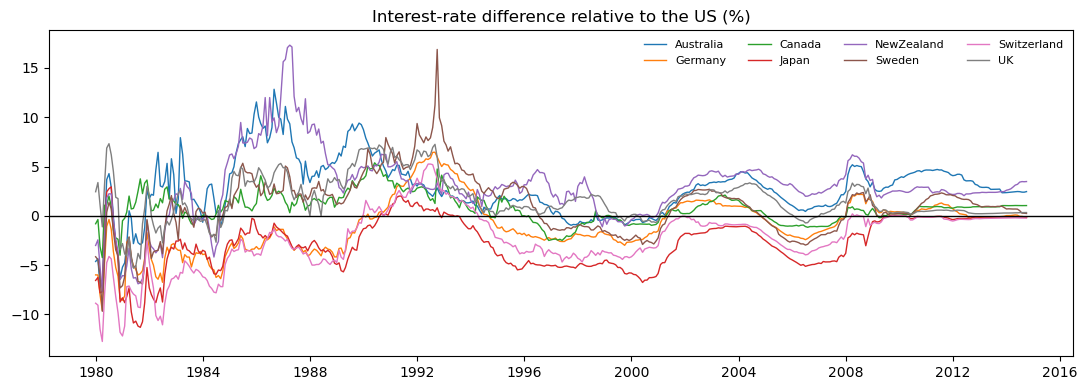

Interpretation: Lines above zero indicate countries offering higher interest rates than the US, creating potential carry returns. However, currency depreciation can offset this advantage.

Average annual returns for a USD investor, 1980–2014 (%):
The return above the US interest rate equals the interest-rate difference plus the currency gain or loss.


,Interest-rate gap,Currency contribution,Realised excess return
NewZealand,+2.95,-0.05,+2.90
Australia,+2.79,-0.14,+2.65
UK,+1.68,-0.55,+1.13
Sweden,+1.03,-1.08,-0.05
Canada,+0.75,+0.29,+1.04
Germany,-0.97,+0.91,-0.06
Switzerland,-2.33,+2.23,-0.11
Japan,-2.79,+2.89,+0.10


Interpretation: Higher-interest-rate currencies, such as the New Zealand and Australian dollars, earned positive excess returns on average.


In [8]:

xr = pd.read_csv("r7_carry_ret.csv", index_col=0, parse_dates=True)
ir = pd.read_csv("r7_carry_rates.csv", index_col=0, parse_dates=True)
FX = [c for c in ir.columns if c != "US"]

gap = ir[FX].sub(ir["US"], axis=0) * 100

# 1. Interest-rate differences
fig, ax = plt.subplots(figsize=(11, 4))
for c in FX:
    ax.plot(gap[c], lw=1, label=c)

ax.axhline(0, color="k", lw=1)
ax.set_title("Interest-rate difference relative to the US (%)")
ax.legend(ncol=4, fontsize=8, frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

print(
    "Interpretation: Lines above zero indicate countries offering higher "
    "interest rates than the US, creating potential carry returns. "
    "However, currency depreciation can offset this advantage."
)

# 2. Average annual carry returns
summary = pd.DataFrame({
    "Interest-rate gap": gap.mean(),
    "Realised excess return": xr[FX].mean() * 12 * 100
})

summary.insert(
    1,
    "Currency contribution",
    summary["Realised excess return"] - summary["Interest-rate gap"]
)

summary = summary.sort_values("Interest-rate gap", ascending=False)

print("\nAverage annual returns for a USD investor, 1980–2014 (%):")
print(
    "The return above the US interest rate equals the interest-rate "
    "difference plus the currency gain or loss."
)

display(
    summary.style.format("{:+.2f}")
    .background_gradient(cmap="RdYlGn", axis=None, vmin=-3, vmax=3)
)

print(
    "Interpretation: Higher-interest-rate currencies, such as the "
    "New Zealand and Australian dollars, earned positive excess returns "
    "on average."
)




**Reading the results:**
- **UIP:** Predicts that exchange-rate movements offset interest-rate differences, resulting in zero excess returns.
- **High-rate currencies:** New Zealand and Australia barely depreciated, allowing investors to earn most of the interest-rate gap (+2.9% and +2.7% annually).
- **Low-rate currencies:** Japan and Switzerland appreciated enough to offset their lower interest rates, broadly consistent with UIP.

### From currencies to a strategy
Now we turn the currencies into two portfolios (long-short and long-only, rebalanced monthly) and look at the full return distribution. 

,Long-short,Long-only
mean,0.05,0.02
vol,0.10,0.08
Sharpe,0.53,0.29
skewness,-1.07,-0.40
worst month,-0.14,-0.12
max drawdown,-0.34,-0.39
excess kurtosis,2.77,2.13


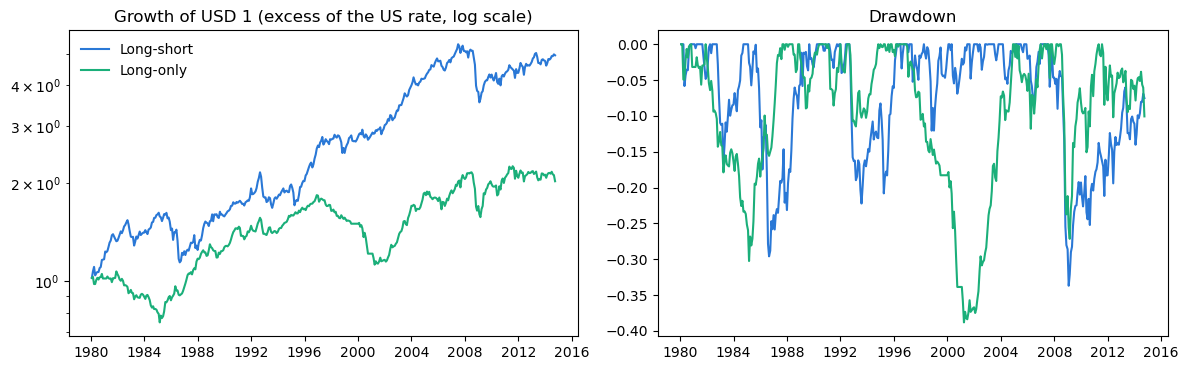

In [9]:
xr = pd.read_csv("r7_carry_ret.csv", index_col=0, parse_dates=True)      # excess return over the US rate, month ending at the date
ir = pd.read_csv("r7_carry_rates.csv", index_col=0, parse_dates=True)    # annual rates at the date
FX = [c for c in ir.columns if c != "US"]

rank = ir.rank(axis=1, method="first")                                   # 1 = lowest rate (US included, as in the book)
w_ls = (rank >= 7).astype(float) / 3 - (rank <= 3).astype(float) / 3     # USD 1 long, USD 1 short
above = ir[FX].gt(ir["US"], axis=0).astype(float)
w_lo = above.div(above.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)  # long-only, equal weights

carry = pd.DataFrame({"Long-short": (w_ls.shift(1) * xr).sum(axis=1),
                      "Long-only": (w_lo.shift(1) * xr[FX]).sum(axis=1)}).iloc[1:]
zero = pd.Series(0.0, index=carry.index)                                 # returns are already in excess of the US rate
ctab = carry.apply(lambda r: stats(r, zero, r)).loc[["mean", "vol", "Sharpe", "skewness", "worst month", "max drawdown"]]
ctab.loc["excess kurtosis"] = carry.kurt()
display(ctab.style.format("{:.2f}"))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, c in {"Long-short": "#2a78d6", "Long-only": "#1baf7a"}.items():
    wealth = (1 + carry[k]).cumprod()
    ax[0].plot(wealth, color=c, label=k)
    ax[1].plot(wealth / wealth.cummax() - 1, color=c, label=k)              # drawdown: fall from the previous peak
ax[0].set_yscale("log"); ax[0].set_title("Growth of USD 1 (excess of the US rate, log scale)")
ax[1].set_title("Drawdown"); ax[0].legend(frameon=False); plt.tight_layout(); plt.show()

**Reading the results:**

- **Long-short:** Sharpe Ratio of **0.53**, but negative skewness (−1.1) indicates frequent small gains and occasional large losses.
- **Long-only:** Lower Sharpe Ratio (**0.29**) and negative skewness (−0.4). Even without short selling, high-rate currencies tend to depreciate during crises.
- **Risk-based point of view:** Carry performs poorly during crises, when investors need money most. Investors therefore demand a **risk premium** to bear this risk.

### Is carry attractive today?

A positive carry opportunity arises when a foreign currency offers a **higher interest rate than the US dollar**. You can gain exposure through a currency ETF, such as FXA (Australian dollar).

In [10]:
rates = pd.read_csv("r7_rates.csv")
FX_ETF = {"Australia": "FXA", "Germany": "FXE", "Canada": "FXC", "Japan": "FXY", "Switzerland": "FXF", "UK": "FXB"}
us = rates.loc[rates["currency"] == "US", "rate"].iloc[0]
rates["carry vs USD (%)"] = rates["rate"] - us
rates["ETF"] = rates["currency"].map(FX_ETF).fillna("-")
print(f"Today's policy rates (US = {us:.2f}%). A long-only carry position needs a currency with a POSITIVE carry vs USD:")
display(rates.sort_values("rate", ascending=False)[["currency", "rate", "carry vs USD (%)", "ETF"]].style.format(
        {"rate": "{:.2f}", "carry vs USD (%)": "{:+.2f}"}))
pos = rates.query("currency != 'US' and `carry vs USD (%)` > 0")["currency"].tolist()
print("-> currencies with positive carry vs USD:", pos if pos else "NONE: for a USD investor the G10 carry trade is not available today")

Today's policy rates (US = 4.00%). A long-only carry position needs a currency with a POSITIVE carry vs USD:


,currency,rate,carry vs USD (%),ETF
9,Brazil,13.75,+9.75,-
11,SouthAfrica,7.25,+3.25,-
10,Mexico,6.25,+2.25,-
1,Australia,4.85,+0.85,FXA
0,US,4.00,+0.00,-
8,UK,4.00,+0.00,FXB
5,NewZealand,2.75,-1.25,-
2,Germany,2.50,-1.50,FXE
3,Canada,2.50,-1.50,FXC
6,Sweden,2.00,-2.00,-


-> currencies with positive carry vs USD: ['Australia', 'Brazil', 'Mexico', 'SouthAfrica']


**Reading the results:** in the TA's example only **Australia** paid more than the US (4.85% vs 4.00%: carry **+0.85%** a year). With our data of 27 November, Brazil, Mexico and South Africa also pay more than the US (the list printed above); the example below keeps the TA's Australian numbers.

**How to build it:** sell USD 1 of other holdings (or cash) and buy USD 1 of **FXA** (an ETF holding Australian dollar deposits). Return over USD cash after one month:

$$R^{FXA}_{t+1} - r^{US}_t \;\approx\; \underbrace{\frac{i_{AUD} - i_{US}}{12}}_{\text{carry: known today}} \;+\; \underbrace{\frac{S_{t+1}-S_t}{S_t}}_{\text{AUD move vs USD: unknown}}$$

With a monthly carry of **+0.07%**, the strategy earns a positive excess return as long as the **USD does not appreciate by more than 0.07% against the AUD**. Any USD depreciation increases the return.

## 5. Size the macro sleeve inside the TE budget
Same method as TA session 6, with one more bet. The portfolio has the SAA ($S$) and three active bets: the Round 2 stock ($A$), the quant stocks ($Q$) and now the macro sleeve ($M$: the picks in `PICKS`, with their weights `SLEEVE`, set in the next cell; in Round 3, Strategy A's bonds: BNDX and BND). We fund $M$ by selling the SAA ETFs in proportion to their SAA weights:

$$R_{new} = (1-w_A-w_Q-w_M)\,R_S + w_A R_A + w_Q R_Q + w_M R_M$$
$$R_{new} - R_S = w_A\,(R_A - R_S) + w_Q\,(R_Q - R_S) + w_M\,(R_M - R_S)$$

**Step 1 – TE per unit of each bet** and the **correlations** of the active returns:
$$\sigma_j = \text{sd}(R_j - R_S)\sqrt{12}, \qquad \rho_{jk} = \text{corr}(R_j - R_S,\; R_k - R_S), \qquad j,k \in \{A, Q, M\}$$

**Step 2 – total TE with three bets:**
$$TE^2 = (w_A\sigma_A)^2 + (w_Q\sigma_Q)^2 + (w_M\sigma_M)^2 + 2\rho_{AQ}\,w_A\sigma_A\,w_Q\sigma_Q + 2\rho_{AM}\,w_A\sigma_A\,w_M\sigma_M + 2\rho_{QM}\,w_Q\sigma_Q\,w_M\sigma_M$$

**Step 3 – fix $w_A$, $w_Q$ (last week) and solve for $w_M$.**

(a) Group the terms of Step 2: those **without** $w_M$, those **linear** in $w_M$, and the **square** in $w_M$:
$$TE^2 = \underbrace{(w_A\sigma_A)^2 + (w_Q\sigma_Q)^2 + 2\rho_{AQ}\,w_A\sigma_A\,w_Q\sigma_Q}_{TE_0^2:\ \text{the TE we already have (A + Q), known}} \;+\; 2\,w_M\sigma_M\underbrace{\big(\rho_{AM}\,w_A\sigma_A + \rho_{QM}\,w_Q\sigma_Q\big)}_{b:\ \text{how M co-moves with A and Q}} \;+\; (w_M\sigma_M)^2$$

(b) Set $TE = 6.5\%$ and move everything to the left: a quadratic in $w_M$:
$$\sigma_M^2\,w_M^2 + 2b\,\sigma_M\,w_M + \big(TE_0^2 - 6.5\%^2\big) = 0$$

(c) Take the positive root:
$$w_M = \frac{-b + \sqrt{b^2 + 6.5\%^2 - TE_0^2}}{\sigma_M}$$


6.5%, not 7%: a buffer, because the TE moves with prices after we trade. 

**Our sizing decision (28 November): we cap the macro sleeve at 7.5% of the NAV (`W_M_MAX`), and the quant sleeve at 12.5% (`W_Q_MAX`, quant notebook 02 §7).** Bonds move little against the SAA, so the 6.5% target alone would allow a macro sleeve of about two thirds of the NAV (printed below): the TE budget cannot limit this bet, a cap must. With a 20% cap and the quant sleeve sized by its own target (34%), more than half of the fund would sit in two strategies whose backtests do not beat their benchmarks: Strategy A earned a Sharpe ratio of 0.51 against 0.59 for our SAA (03b), and the quant sleeve 0.56 against 0.65 for the Russell 1000. Equity would reach 54% of the NAV against 31% in our SAA, and gold and commodities would fall to 9% against 24%, although our view is stagflation.

The portfolio cannot change before 27 December, two releases inside the month can end the regime (CPI on 10 December, CFNAI on 21 December), and the growth signal is borderline (CFNAI 3-month average −0.05). So we size each bet to the strength of its evidence: **2% for each Round 2 stock, 12.5% quant, 7.5% macro, and the remaining 72% in the SAA**. The tracking error is about 2.3%, well inside the 7% budget, and the volatility and VaR are those of the SAA (table below). We set the caps after seeing the composition of the portfolio, not to improve a backtest: the signals, the stocks and the regime rule are unchanged.

**The instruments: BNDX and BND, in their SAA proportion.** The regime rule of 03b holds the asset class with the best past Sharpe ratio in the current regime. In the 86 stagflation months that is BNDX (0.75), but BND (0.71) cannot be told apart from it: the difference is 0.04 a year with a standard error of 0.12 (z = 0.34), and their returns have a correlation of 0.95 (notebook 03b, §4b). We hold both, in their SAA proportion (BNDX 55.3%, BND 44.7%), rather than make a choice the data cannot support. In the 03b backtest the split leaves the Sharpe ratio almost unchanged (0.506 against 0.509 over 2002–2026). We decided it after seeing the backtest, so we log it as a fourth trial of Strategy A.

In [11]:
PICKS  = ["BNDX", "BND"]                     # Strategy A (03b): Stagflation -> bonds; BNDX and BND cannot be told apart (03b §4b)
N_TOP  = len(PICKS)
SLEEVE = W_SAA[PICKS] / W_SAA[PICKS].sum()   # weights inside the macro sleeve: their SAA proportion (BNDX 55.3%, BND 44.7%)

In [12]:

prices = pd.read_csv(R3 + "r3_prices.csv", index_col=0, parse_dates=True)
rf3    = pd.read_csv(R3 + "r3_rf.csv", index_col=0, parse_dates=True)["rf"]
port3  = pd.read_csv(R3 + "r3_portfolio.csv", index_col=0)
w3     = port3["weight"].drop("CASH")

# ---- Step 1: monthly excess returns, last 60 months -------------------------------------------
extra = [p for p in PICKS if p not in prices]                              # picks priced only in r7_countries.csv
allp  = prices.join(P[extra], how="inner") if extra else prices
assert allp.index[-1] == prices.index[-1], "the macro window must end where the quant one ends"
R    = allp.pct_change(fill_method=None).iloc[1:]
est  = R.sub(rf3.reindex(R.index).ffill(), axis=0).iloc[-WINDOW:]

# ---- Step 2: the four building blocks ------------------------------------------------------------
A_TICK = ["NVDA", "PEP", "ABBV", "DRI"]          # Round 2 stocks kept, 2% each (quant 02 W_R2)
Q_TICK = [t for t in w3.index if t not in ETFS + A_TICK]
w_A, w_Q = w3[A_TICK].sum(), w3[Q_TICK].sum()

R_S = est[ETFS] @ W_SAA
R_A = est[A_TICK] @ (w3[A_TICK] / w_A)
R_Q = est[Q_TICK].mean(axis=1)
R_M = est[PICKS] @ SLEEVE

blocks = pd.DataFrame({
    "SAA": R_S,
    "Round 2 (A)": R_A,
    "Quant (Q)": R_Q,
    "Macro (M)": R_M
})

print(f"Months used: {len(est)} ({est.index[0]:%b %Y} - {est.index[-1]:%b %Y})")
print("\nCORRELATIONS of the returns (how the four blocks move together):")
display(blocks.corr().style.format("{:+.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))

# ---- Step 3: calculate active risk (no intermediate output) -------------------------------------
act = pd.DataFrame({
    "A": R_A - R_S,
    "Q": R_Q - R_S,
    "M": R_M - R_S
})

sig = act.std() * np.sqrt(12)
rho = act.corr()

# ---- Step 4: calculate remaining tracking-error budget ------------------------------------------
a, q = w_A * sig["A"], w_Q * sig["Q"]

TE0 = np.sqrt(
    a**2 + q**2 + 2 * rho.loc["A", "Q"] * a * q
)

b = rho.loc["A", "M"] * a + rho.loc["Q", "M"] * q

w_M_budget = (-b + np.sqrt(b**2 + TE_TARGET**2 - TE0**2)) / sig["M"]
w_M = min(w_M_budget, W_M_MAX)

def te(w):
    return (w_A * act["A"] + w_Q * act["Q"] + w * act["M"]).std() * np.sqrt(12)

print(f"\nw_A = {w_A:.1%}, w_Q = {w_Q:.1%}  ->  TE before macro = {TE0:.2%}   (direct check: {te(0):.2%})")
print(f"Solving TE^2 = {TE_TARGET:.1%}^2  ->  w_M = {w_M_budget:.1%} allowed by the budget")
per_pick = ", ".join(f"{t} {w_M * s:.1%}" for t, s in SLEEVE.items())    # weight of each pick in the NAV
print(
    f"-> we invest w_M = {w_M:.1%} of the NAV "
    f"({per_pick}): TE = {te(w_M):.2%}"
    + ("   (capped by W_M_MAX)" if w_M < w_M_budget else "")
)

# ---- Step 5: risk of the new portfolio ----------------------------------------------------------
R_P3  = R_S + w_A * act["A"] + w_Q * act["Q"]
R_new = R_P3 + w_M * act["M"]

vol = lambda r: r.std() * np.sqrt(12)

display(
    pd.DataFrame({
        "SAA": [
            vol(R_S),
            1.645 * vol(R_S) / np.sqrt(12),
            0.0
        ],
        "Round 3 before macro": [
            vol(R_P3),
            1.645 * vol(R_P3) / np.sqrt(12),
            te(0)
        ],
        "Round 3 with macro": [
            vol(R_new),
            1.645 * vol(R_new) / np.sqrt(12),
            te(w_M)
        ]
    }, index=[
        "Volatility (annual)",
        "VaR 5%, 1 month",
        "Tracking error vs SAA"
    ]).style.format("{:.1%}")
)


Months used: 60 (Nov 2021 - Oct 2026)

CORRELATIONS of the returns (how the four blocks move together):


,SAA,Round 2 (A),Quant (Q),Macro (M)
SAA,+1.00,+0.62,+0.48,+0.76
Round 2 (A),+0.62,+1.00,+0.49,+0.60
Quant (Q),+0.48,+0.49,+1.00,+0.36
Macro (M),+0.76,+0.60,+0.36,+1.00



w_A = 8.0%, w_Q = 12.5%  ->  TE before macro = 2.21%   (direct check: 2.21%)
Solving TE^2 = 6.5%^2  ->  w_M = 108.5% allowed by the budget
-> we invest w_M = 7.5% of the NAV (BNDX 4.1%, BND 3.4%): TE = 2.27%   (capped by W_M_MAX)


,SAA,Round 3 before macro,Round 3 with macro
Volatility (annual),8.4%,8.7%,8.4%
"VaR 5%, 1 month",4.0%,4.1%,4.0%
Tracking error vs SAA,0.0%,2.2%,2.3%


## 6. Portfolio description and trades (for the report and PRTU)
- **SAA ETFs:** $w^{new}_j = w^{R3}_j - w_M\cdot \dfrac{w^{SAA}_j}{\sum_k w^{SAA}_k}$ (we sell them to fund the sleeve)
- **Macro picks:** $w^{new}_c = w_M \cdot s_c$ for each pick $c$ in `PICKS`, with $s_c$ its weight in `SLEEVE`. A pick that is also an SAA ETF (BNDX and BND in Round 3) keeps one row with both weights, labelled "SAA + Macro"
- **Round 2 stocks and quant stocks:** unchanged from quant notebook 02, with its sleeve labels

$$\text{shares}^{new} = \left\lfloor \frac{w^{new}\cdot NAV}{P}\right\rfloor, \qquad \text{trade} = \text{shares}^{new} - \text{shares}^{Round\,2}$$

The trade column is the **full list for PRTU**: the quant trades of last week and the macro trades of today, entered together on 28–29 November.

In [13]:
live = pd.read_csv("r7_live.csv").set_index("ticker")
NAV  = port3["USD"].sum()                                              # the NAV of quant 02 (its shares and cash come from PORT, B8)

w_new = w3.copy()
w_new[ETFS] -= w_M * W_SAA / W_SAA.sum()
w_new = pd.concat([w_new, w_M * SLEEVE]).groupby(level=0).sum()   # adds up if a pick is also an SAA ETF (BNDX, BND)

port = pd.DataFrame(index=w_new.index)
port["name"]       = port3["name"].reindex(port.index).fillna(live["name"])
port["Bloomberg"]  = [t + " US Equity" for t in port.index]
port["currency"]   = "USD"
port["sleeve"]     = [("SAA + Macro" if t in ETFS else "Macro") if t in PICKS     # a pick that is also an SAA ETF
                      else port3["sleeve"].get(t, "Quant") for t in port.index]  # quant 02: SAA, Round 2, Quant
port["weight"]     = w_new
port["price"]      = port3["price"].reindex(port.index).fillna(live["px_last"])
port["price date"] = "2026-11-27"                                           # closes of Fri 27 Nov 2026
assert port["price"].notna().all(), "a position has no price"
port["shares"]     = np.floor(port["weight"] * NAV / port["price"] + 1e-9)
port["old shares"] = port3["old shares"].reindex(port.index).fillna(0)  # Round 2 holdings
port["trade"]      = port["shares"] - port["old shares"]
port["USD"]        = port["shares"] * port["price"]
port.loc["CASH", ["weight", "USD"]] = [1 - port["weight"].sum(), NAV - port["USD"].sum()]
port.to_csv("r7_portfolio.csv")

print(f"NAV = USD {NAV:,.0f} | positions: {(port['shares'] > 0).sum()} | TE vs SAA: {te(w_M):.2%} (limit {TE_MAX:.0%})")
print("Weight by sleeve:", port.groupby("sleeve")["weight"].sum().round(3).to_dict())
print(f"Macro sleeve: w_M = {w_M:.1%} of the NAV in {', '.join(PICKS)}"
      + ("; a pick that is an SAA ETF keeps its SAA weight in the same row (sleeve 'SAA + Macro')" if set(PICKS) & set(ETFS) else ""))
port[port["sleeve"].isin(["Macro", "SAA + Macro", "SAA"])].sort_values("weight", ascending=False)

NAV = USD 96,827,577 | positions: 41 | TE vs SAA: 2.27% (limit 7%)
Weight by sleeve: {'Quant': 0.125, 'Round 2': 0.08, 'SAA': 0.505, 'SAA + Macro': 0.29}
Macro sleeve: w_M = 7.5% of the NAV in BNDX, BND; a pick that is an SAA ETF keeps its SAA weight in the same row (sleeve 'SAA + Macro')


,name,Bloomberg,currency,sleeve,weight,price,price date,shares,old shares,trade,USD
BNDX,VANGUARD TOTAL INTL BOND ETF,BNDX US Equity,USD,SAA + Macro,0.1601,47.6100,2026-11-27,325641.0000,265436.0000,60205.0000,15503768.0100
BND,VANGUARD TOTAL BOND MARKET,BND US Equity,USD,SAA + Macro,0.1295,71.3800,2026-11-27,175684.0000,142724.0000,32960.0000,12540323.9200
TIP,ISHARES TIPS BOND ETF,TIP US Equity,USD,SAA,0.1099,105.6700,2026-11-27,100676.0000,110068.0000,-9392.0000,10638432.9200
BCI,ABRDN BLOOMBERG ALL COMMODIT,BCI US Equity,USD,SAA,0.0893,23.5700,2026-11-27,366766.0000,385745.0000,-18979.0000,8644674.6200
GLD,SPDR GOLD SHARES,GLD US Equity,USD,SAA,0.0803,334.4000,2026-11-27,23245.0000,22942.0000,303.0000,7773128.0000
VTI,VG MORNINGSTAR TS MKT ETF-US,VTI US Equity,USD,SAA,0.0785,359.4000,2026-11-27,21143.0000,23084.0000,-1941.0000,7598794.2000
VEA,VANGUARD FTSE DEVELOPED ETF,VEA US Equity,USD,SAA,0.0737,66.8600,2026-11-27,106772.0000,115597.0000,-8825.0000,7138775.9200
IEMG,ISHARES CORE MSCI EMERGING,IEMG US Equity,USD,SAA,0.0737,70.8400,2026-11-27,100675.0000,108607.0000,-7932.0000,7131817.0000
